## Media Pipe and Xgboost refactored, godbless Kazim and curse kaggle thanks

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import mediapipe as mp
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, classification_report
from xgboost import XGBClassifier


TRAIN_ROOT = Path('../data/dataset/D01_megadataset/')
EXTERNAL_ROOT = Path('../data/dataset/Testing/')

LETTERS = "ABCDEFGHIKLMNOPQRSTUVWXY"
LABEL_MAP = {letter: index for index, letter in enumerate(LETTERS)}

HAND_MODEL = Path("../models/hand_landmarker.task")
HAND_MODEL.parent.mkdir(parents=True, exist_ok=True)

MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "hand_landmarker/hand_landmarker/float16/1/"
    "hand_landmarker.task"
)

if not HAND_MODEL.exists():
    urlretrieve(MODEL_URL, HAND_MODEL)

print("MediaPipe model:", HAND_MODEL)

MediaPipe model: ../models/hand_landmarker.task


In [2]:
def create_landmarker():
    options = mp.tasks.vision.HandLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(
            model_asset_path=str(HAND_MODEL)
        ),
        running_mode=mp.tasks.vision.RunningMode.IMAGE,
        num_hands=1,
        min_hand_detection_confidence=0.5,
        min_hand_presence_confidence=0.5,
    )

    return mp.tasks.vision.HandLandmarker.create_from_options(options)

In [3]:
landmarker = create_landmarker()
print(landmarker)

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792491554.883789    5599 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792491554.934735    5599 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [4]:
def find_images(root):
    root = Path(root)

    if not root.is_dir():
        raise FileNotFoundError(root)

    paths, labels = [], []

    for path in sorted(root.rglob("*")):
        if not path.is_file():
            continue

        if path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
            continue

        letter = path.parent.name.upper()

        if letter in LABEL_MAP:
            paths.append(path)
            labels.append(LABEL_MAP[letter])

    if not paths:
        raise ValueError(f"No images in supported letter folders: {root}")

    return paths, np.array(labels, dtype=np.int64)

In [5]:
paths, labels = find_images('../data/dataset/D01_megadataset/')

In [6]:
labels

array([ 0,  0,  0, ..., 23, 23, 23], shape=(138199,))

In [7]:
def read_rgb(path):
    with Image.open(path) as original:
        oriented = ImageOps.exif_transpose(original).convert("RGBA")
        background = Image.new(
            "RGBA", oriented.size, (255, 255, 255, 255)
        )
        image = Image.alpha_composite(
            background, oriented
        ).convert("RGB")

        # Limit large images while preserving aspect ratio.
        image.thumbnail((1024, 1024), Image.Resampling.LANCZOS)

        return np.array(image)

In [8]:
read_rgb(paths[0])

array([[[180, 180, 182],
        [179, 179, 181],
        [179, 179, 181],
        ...,
        [170, 163, 157],
        [169, 162, 156],
        [169, 162, 156]],

       [[180, 180, 182],
        [180, 180, 182],
        [180, 180, 182],
        ...,
        [171, 164, 158],
        [170, 163, 157],
        [170, 163, 157]],

       [[180, 180, 182],
        [180, 180, 182],
        [180, 180, 182],
        ...,
        [171, 164, 158],
        [170, 163, 157],
        [170, 163, 157]],

       ...,

       [[169, 173, 182],
        [168, 172, 181],
        [168, 171, 176],
        ...,
        [164, 158, 158],
        [164, 160, 161],
        [165, 160, 164]],

       [[168, 171, 178],
        [167, 170, 177],
        [167, 172, 178],
        ...,
        [164, 158, 160],
        [162, 158, 159],
        [163, 159, 160]],

       [[168, 171, 176],
        [167, 170, 175],
        [167, 171, 180],
        ...,
        [162, 156, 158],
        [162, 158, 159],
        [163, 159, 160]]

In [9]:
def get_features(rgb, landmarker):
    image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=np.ascontiguousarray(rgb),
    )

    result = landmarker.detect(image)

    if not result.hand_landmarks:
        return None, None

    points = np.array(
        [[point.x, point.y, point.z]
         for point in result.hand_landmarks[0]],
        dtype=np.float32,
    )

    # Express coordinates in consistent units.
    height, width = rgb.shape[:2]
    points *= np.array([width, height, width], dtype=np.float32)

    # Wrist becomes the origin.
    relative = points - points[0]

    # Normalize by wrist-to-middle-finger-knuckle distance.
    scale = np.linalg.norm(relative[9])

    if scale < 1e-6:
        return None, None

    features = (relative / scale).reshape(-1)

    # 21 points × 3 coordinates = 63 features.
    return features, result.hand_landmarks[0]

In [10]:
features, results = get_features(read_rgb(paths[0]), landmarker)

W0000 00:00:1792491589.202024    5601 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


In [11]:
features

array([ 0.        ,  0.        ,  0.        ,  0.5425894 , -0.12303537,
       -0.09943495,  0.92811215, -0.55003834, -0.12547189,  0.98420477,
       -1.0245322 , -0.14438625,  0.8651539 , -1.3241539 , -0.12846763,
        0.67111903, -0.95793533, -0.12231584,  0.6279113 , -1.3069147 ,
       -0.33711302,  0.5643088 , -0.9232701 , -0.45695055,  0.57157207,
       -0.7912812 , -0.5292366 ,  0.30229065, -0.939389  , -0.16176733,
        0.28138617, -1.2487346 , -0.33456928,  0.28771788, -0.7972643 ,
       -0.35321346,  0.32262796, -0.7384525 , -0.37097716, -0.02947702,
       -0.8769324 , -0.22955011, -0.02639486, -1.109801  , -0.42591938,
        0.0096449 , -0.707677  , -0.3471768 ,  0.04504041, -0.651664  ,
       -0.2808875 , -0.34424397, -0.8030014 , -0.30529368, -0.32408366,
       -0.9316422 , -0.41894606, -0.2635947 , -0.6775326 , -0.35276705,
       -0.24778894, -0.6237741 , -0.30288777], dtype=float32)

In [12]:
features.shape

(63,)

In [13]:
results

[NormalizedLandmark(x=0.45226725935935974, y=0.8480645418167114, z=-1.055338429978292e-06, visibility=None, presence=None, name=None),
 NormalizedLandmark(x=0.6494672298431396, y=0.8033483028411865, z=-0.03613992780447006, visibility=None, presence=None, name=None),
 NormalizedLandmark(x=0.7895825505256653, y=0.6481573581695557, z=-0.04560285061597824, visibility=None, presence=None, name=None),
 NormalizedLandmark(x=0.8099689483642578, y=0.47570616006851196, z=-0.05247713252902031, visibility=None, presence=None, name=None),
 NormalizedLandmark(x=0.766700804233551, y=0.36681100726127625, z=-0.04669163376092911, visibility=None, presence=None, name=None),
 NormalizedLandmark(x=0.6961803436279297, y=0.4999103248119354, z=-0.04445581138134003, visibility=None, presence=None, name=None),
 NormalizedLandmark(x=0.6804768443107605, y=0.3730764389038086, z=-0.12252220511436462, visibility=None, presence=None, name=None),
 NormalizedLandmark(x=0.6573610305786133, y=0.5125091075897217, z=-0.166

In [14]:
len(results)

21

In [15]:
def extract_features(paths):
    # NaN rows preserve failures in their original positions.
    features = np.full((len(paths), 63), np.nan, dtype=np.float32)
    failures = []

    with create_landmarker() as landmarker:
        for index, path in enumerate(tqdm(paths)):
            try:
                rgb = read_rgb(path)
                vector, _ = get_features(rgb, landmarker)

                if vector is None:
                    failures.append((str(path), "No usable hand landmarks"))
                else:
                    features[index] = vector

            except (OSError, ValueError, RuntimeError) as error:
                failures.append((str(path), str(error)))

    return features, failures

In [16]:
features, failures = extract_features(paths)

W0000 00:00:1792491598.083425    5731 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792491598.104627    5732 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  0%|          | 0/138199 [00:00<?, ?it/s]

In [17]:
features

array([[ 0.        ,  0.        ,  0.        , ..., -0.24778894,
        -0.6237741 , -0.30288777],
       [ 0.        ,  0.        ,  0.        , ..., -0.2693244 ,
        -0.61628467, -0.25480676],
       [ 0.        ,  0.        ,  0.        , ..., -0.25678167,
        -0.7853522 , -0.1754351 ],
       ...,
       [ 0.        ,  0.        ,  0.        , ..., -0.9120789 ,
        -1.3391516 , -0.32233876],
       [ 0.        ,  0.        ,  0.        , ..., -0.8298154 ,
        -1.4395517 , -0.30060112],
       [ 0.        ,  0.        ,  0.        , ..., -0.80050665,
        -1.4088831 , -0.31374446]], shape=(138199, 63), dtype=float32)

In [18]:
failures

[('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1002.jpg',
  'No usable hand landmarks'),
 ('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1002_copy.jpg',
  'No usable hand landmarks'),
 ('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1004.jpg',
  'No usable hand landmarks'),
 ('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1004_copy.jpg',
  'No usable hand landmarks'),
 ('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1005.jpg',
  'No usable hand landmarks'),
 ('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1005_copy.jpg',
  'No usable hand landmarks'),
 ('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1006.jpg',
  'No usable hand landmarks'),
 ('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1006_copy.jpg',
  'No usable hand landmarks'),
 ('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1007.jpg',
  'No usable hand landmarks'),
 ('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1007_copy.jpg',
  'No usable hand landmarks'),
 ('../data/dataset/D01_me

W0000 00:00:1792495017.065122   15807 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792495017.198082   15806 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


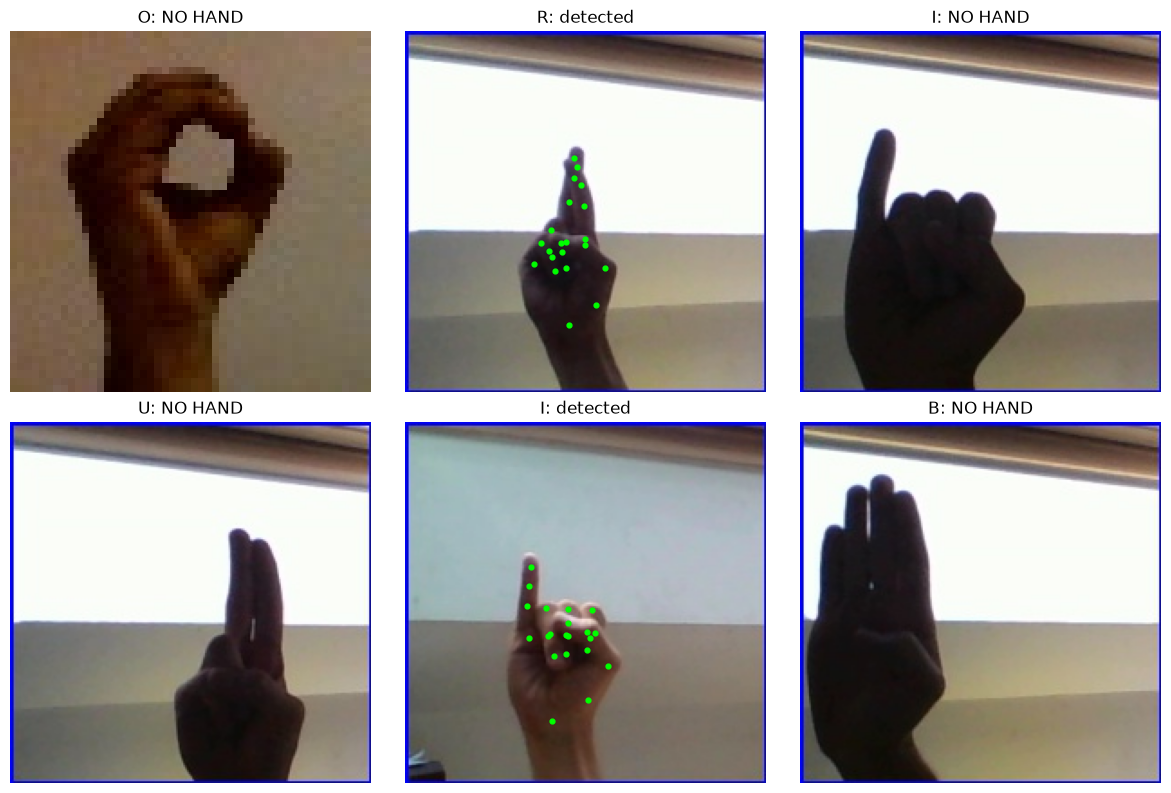

In [19]:
train_paths, train_labels = find_images(TRAIN_ROOT)

sample_indices = np.random.default_rng(42).choice(
    len(train_paths),
    size=min(6, len(train_paths)),
    replace=False,
)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax in axes.flat:
    ax.axis("off")

with create_landmarker() as landmarker:
    for ax, index in zip(axes.flat, sample_indices):
        rgb = read_rgb(train_paths[index])
        _, landmarks = get_features(rgb, landmarker)

        ax.imshow(rgb)

        if landmarks:
            height, width = rgb.shape[:2]
            ax.scatter(
                [point.x * width for point in landmarks],
                [point.y * height for point in landmarks],
                s=12,
                c="lime",
            )
            status = "detected"
        else:
            status = "NO HAND"

        ax.set_title(f"{LETTERS[train_labels[index]]}: {status}")

plt.tight_layout()
plt.show()

In [20]:
train_indices, val_indices = train_test_split(
    np.arange(len(train_paths)),
    test_size=0.2,
    random_state=42,
    stratify=train_labels,
)

# Extract once, then select the corresponding rows.
features_all, training_failures = extract_features(train_paths)

X_train = features_all[train_indices]
y_train = train_labels[train_indices]

X_val = features_all[val_indices]
y_val = train_labels[val_indices]

train_ok = np.isfinite(X_train).all(axis=1)

print(f"Training hand detection: {train_ok.mean():.1%}")
print("First loading/detection failures:", training_failures[:3])

# All 24 classes must have usable training examples.
missing = set(range(24)) - set(y_train[train_ok])

if missing:
    raise ValueError(
        f"No usable training images for: {[LETTERS[i] for i in sorted(missing)]}"
    )

W0000 00:00:1792495039.437602   15882 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792495039.518373   15882 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  0%|          | 0/138199 [00:00<?, ?it/s]

Training hand detection: 80.1%
First loading/detection failures: [('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1002.jpg', 'No usable hand landmarks'), ('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1002_copy.jpg', 'No usable hand landmarks'), ('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1004.jpg', 'No usable hand landmarks')]


In [173]:
classifier = XGBClassifier(
    objective="multi:softprob",
    num_class=25,
    n_estimators=400,
    max_depth=3,
    learning_rate=0.04,
    subsample=0.8,
    min_child_weight=3,
    reg_lambda=5,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="mlogloss",
    #early_stopping_rounds= 80,
    random_state=42,
    n_jobs=4,
)

classifier.fit(
    X_train[train_ok],
    y_train[train_ok],
    eval_set=[(X_val, y_val)],
    verbose=False
)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn

In [ ]:
""" SgdClassifier = SGDClassifier(
    loss='log_loss',
    alpha=0.0001,
    max_iter=2000,
    random_state=42,
    penalty='l2',
    learning_rate='adaptive',
    eta0=0.01,
    n_iter_no_change=10,
    tol=1e-4,
    early_stopping=True
)
SgdClassifier.fit(
    X_train[train_ok],
    y_train[train_ok]
) """

,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'log_loss'
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",2000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.0001
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"learning_rate learning_rate: str, default='optimal'The learning rate schedule:- 'constant': `eta = eta0`- 'optimal': `eta = 1.0 / (alpha * (t + t0))` where `t0` is chosen by a heuristic proposed by Leon Bottou.- 'invscaling': `eta = eta0 / pow(t, power_t)`- 'adaptive': `eta = eta0`, as long as the training keeps decreasing. Each time n_iter_no_change consecutive epochs fail to decrease the training loss by tol or fail to increase validation score by tol if `early_stopping` is `True`, the current learning rate is divided by 5.- 'pa1': passive-aggressive algorithm 1, see [1]_. Only with `loss='hinge'`. Update is `w += eta y x` with `eta = min(eta0, loss/||x||**2)`.- 'pa2': passive-aggressive algorithm 2, see [1]_. Only with `loss='hinge'`. Update is `w += eta y x` with `eta = hinge_loss / (||x||**2 + 1/(2 eta0))`... versionadded:: 0.20 Added 'adaptive' option... versionadded:: 1.8 Added options 'pa1' and 'pa2'",'adaptive'
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to `True`, it will automatically set asidea stratified fraction of training data as validation and terminatetraining when validation score returned by the `score` method is notimproving by at least tol for n_iter_no_change consecutive epochs.See :ref:`sphx_glr_auto_examples_linear_model_plot_sgd_early_stopping.py` for anexample of the effects of early stopping... versionadded:: 0.20 Added 'early_stopping' option",True
,"n_iter_no_change n_iter_no_change: in

In [176]:
def evaluate_pipeline(classifier, features, labels, name):
    usable = np.isfinite(features).all(axis=1)

    # -1 means no prediction; always incorrect for our letter labels.
    predictions = np.full(len(labels), -1, dtype=np.int64)

    if usable.any():
        predictions[usable] = classifier.predict(
            features[usable]
        ).astype(np.int64)

    print(f"\n{name}")
    print(f"Images: {len(labels)}")
    print(f"Usable hand detection: {usable.mean():.2%}")
    print(f"Overall accuracy: {(predictions == labels).mean():.2%}")

    if usable.any():
        accuracy = accuracy_score(
            labels[usable], predictions[usable]
        )
        print(f"Accuracy on detected hands: {accuracy:.2%}")

    return predictions


val_predictions = evaluate_pipeline(
    classifier, X_val, y_val, "Validation"
)


Validation
Images: 27640
Usable hand detection: 79.85%
Overall accuracy: 79.27%
Accuracy on detected hands: 99.27%


In [177]:
external_paths, y_external = find_images(EXTERNAL_ROOT)

X_external, external_failures = extract_features(external_paths)

external_predictions = evaluate_pipeline(
    classifier,
    X_external,
    y_external,
    "ASLYset external evaluation",
)

W0000 00:00:1792511862.577051   71501 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792511862.925972   71502 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  0%|          | 0/745 [00:00<?, ?it/s]


ASLYset external evaluation
Images: 745
Usable hand detection: 73.56%
Overall accuracy: 65.37%
Accuracy on detected hands: 88.87%


In [ ]:
import json
from pathlib import Path

output_dir = Path("models")
output_dir.mkdir(parents=True, exist_ok=True)

classifier.save_model(
    str(output_dir / "handspell_xgboost_v1.json")
)

metadata = {
    "letters": LETTERS,
    "feature_count": 63,
    "normalization": "wrist origin; wrist-to-middle-MCP distance",
    "external_accuracy": 0.6456,
}

(output_dir / "handspell_xgboost_v1_metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("Model and metadata saved.")

Model and metadata saved.


In [128]:
import joblib

with open('handspell_xgboost_megadata.joblib',"wb") as file:
    joblib.dump(classifier, file)

In [165]:
print(classification_report(
    y_external,
    external_predictions,
    labels=np.arange(24),
    target_names=list(LETTERS),
    digits=3,
    zero_division=0,
))

              precision    recall  f1-score   support

           A      0.576     0.613     0.594        31
           B      0.912     1.000     0.954        31
           C      0.969     1.000     0.984        31
           D      0.775     1.000     0.873        31
           E      0.000     0.000     0.000        31
           F      1.000     1.000     1.000        31
           G      0.963     0.812     0.881        32
           H      1.000     1.000     1.000        31
           I      0.935     0.935     0.935        31
           K      0.920     0.742     0.821        31
           L      1.000     1.000     1.000        31
           M      0.000     0.000     0.000        31
           N      1.000     0.065     0.121        31
           O      0.667     0.065     0.118        31
           P      1.000     1.000     1.000        31
           Q      0.939     1.000     0.969        31
           R      0.939     1.000     0.969        31
           S      0.000    

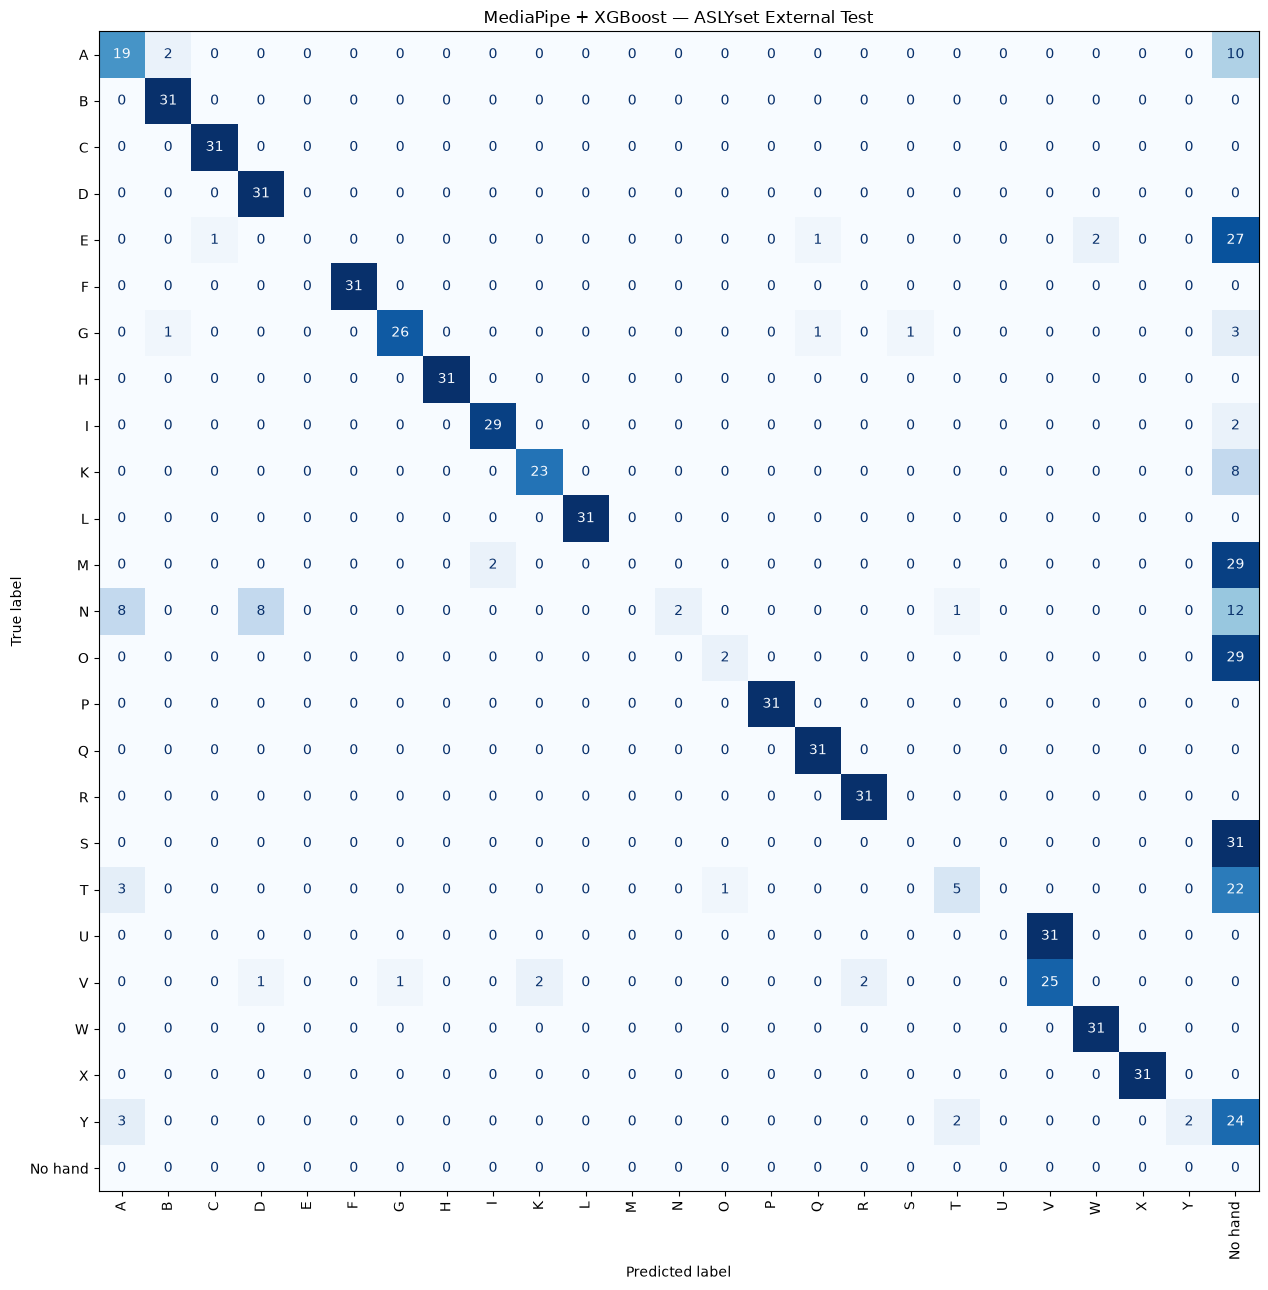

In [166]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Your existing 24-letter mapping.
LETTERS = "ABCDEFGHIKLMNOPQRSTUVWXY"

# Convert failure value -1 to index 24 for display.
predictions = np.where(
    external_predictions == -1,
    24,
    external_predictions,
)

display_labels = list(LETTERS) + ["No hand"]

matrix = confusion_matrix(
    y_external,
    predictions,
    labels=np.arange(25),
)

fig, ax = plt.subplots(figsize=(16, 13))

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=display_labels,
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=90,
    colorbar=False,
)

ax.set_title("MediaPipe + XGBoost — ASLYset External Test")
plt.tight_layout()
plt.show()